# Multi-Class Benchmark Classification Pipeline — Iris Dataset


## Project objective
Build and compare two supervised multi-class classification models:
- Logistic Regression
- Decision Tree Classifier

We will predict the Iris flower species from four measurements and evaluate the models using accuracy, precision, recall, F1-score and confusion matrices.






## Phase 1 — Frame the problem

### Step 1: Understand the business problem

**Problem statement:** Given the sepal and petal measurements of an Iris flower, predict whether it belongs to the species *setosa*, *versicolor* or *virginica*.

- **Learning type:** Supervised learning, because the correct species label is supplied.
- **Problem type:** Multi-class classification, because the target has three categories.
- **Features (X):** `sepal_length`, `sepal_width`, `petal_length`, `petal_width`.
- **Target (y):** `species`.

**How success will be measured:** Compare test-set accuracy, weighted precision, weighted recall and weighted F1-score. Also inspect confusion matrices to see which species are confused with one another.


## Step 2: Collect the data



### Import libraries

In [0]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Scikit-learn tools for splitting, scaling, modelling and evaluation
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)


###Data Ingestion

In [0]:
df= spark.read.table("workspace.datheon.datheon_task_1")

# Display the  records to check that the file loaded correctly.
display(df)

#Convert to Pandas dataframe

df= df.toPandas()

df.head()

sepal_length,sepal_width,petal_length,petal_width,species
5.1,3.5,1.4,0.2,setosa
4.9,3.0,1.4,0.2,setosa
4.7,3.2,1.3,0.2,setosa
4.6,3.1,1.5,0.2,setosa
5.0,3.6,1.4,0.2,setosa
5.4,3.9,1.7,0.4,setosa
4.6,3.4,1.4,0.3,setosa
5.0,3.4,1.5,0.2,setosa
4.4,2.9,1.4,0.2,setosa
4.9,3.1,1.5,0.1,setosa


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


### Data inspection



In [0]:
# Check the number of rows and columns.
# Check the number of rows and columns.
print("Dataset shape:", (df.count(), len(df.columns)))
print("Column names:", df.columns)


Dataset shape: (sepal_length    150
sepal_width     150
petal_length    150
petal_width     150
species         150
dtype: int64, 5)
Column names: Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species'],
      dtype='object')


## Phase 2 — Prepare the data

### Step 3: Clean the data


In [0]:
# Inspect data types and non-null counts.
df.info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [0]:
# Count missing values in each column.
print("\\nMissing values per column:")
print(df.isna().sum())



\nMissing values per column:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


In [0]:
# Count exact duplicate rows before cleaning.
duplicate_count = df.duplicated().sum()
print("\\nExact duplicate rows:", duplicate_count)



\nExact duplicate rows: 1


In [0]:
# Remove exact duplicate rows and reset the row index.
df = df.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df.shape)



Shape after removing duplicates: (149, 5)


In [0]:
# Confirm that no missing values remain.
print("\\nMissing values after cleaning:")
print(df.isna().sum())

\nMissing values after cleaning:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


In [0]:
# Summary statistics for the four numeric measurements.
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,149.000000,149.000000,149.000000,149.000000
mean,5.843624,3.059732,3.748993,1.194631
std,0.830851,0.436342,1.767791,0.762622
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.300000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


## Step 4: Explore and understand the data (EDA)

EDA helps us understand distributions, class balance and relationships between measurements before training.

We will use:
1. Summary statistics.
2. Species counts.
3. Histograms.
4. A Pandas scatter-matrix as a pairplot alternative.
5. A correlation matrix.


Species counts:
species
setosa        50
versicolor    50
virginica     49
Name: count, dtype: int64


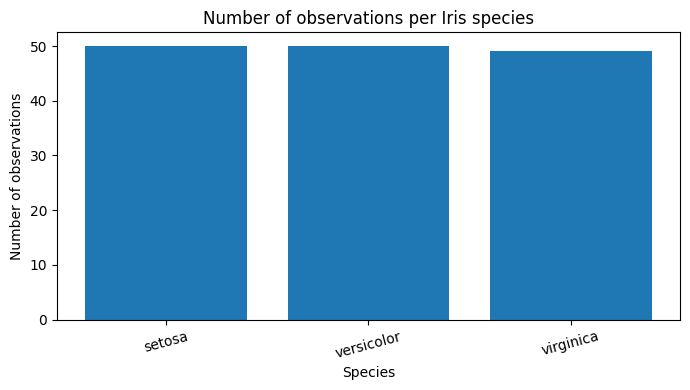

In [0]:
# Check how many observations belong to each species.
print("Species counts:")
print(df["species"].value_counts())

# Plot the number of records in each species.
species_counts = df["species"].value_counts()
plt.figure(figsize=(7, 4))
plt.bar(species_counts.index, species_counts.values)
plt.title("Number of observations per Iris species")
plt.xlabel("Species")
plt.ylabel("Number of observations")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

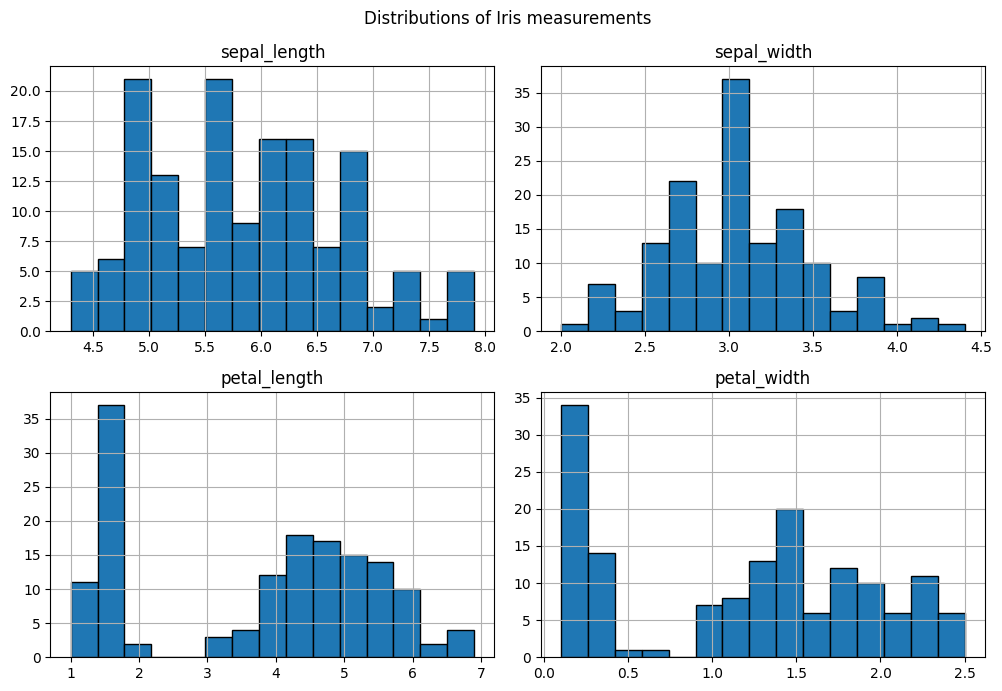

In [0]:
# Plot a histogram for each numeric feature to inspect its distribution.
numeric_columns = ["sepal_length", "sepal_width", "petal_length", "petal_width"]

df[numeric_columns].hist(figsize=(10, 7), bins=15, edgecolor="black")
plt.suptitle("Distributions of Iris measurements")
plt.tight_layout()
plt.show()

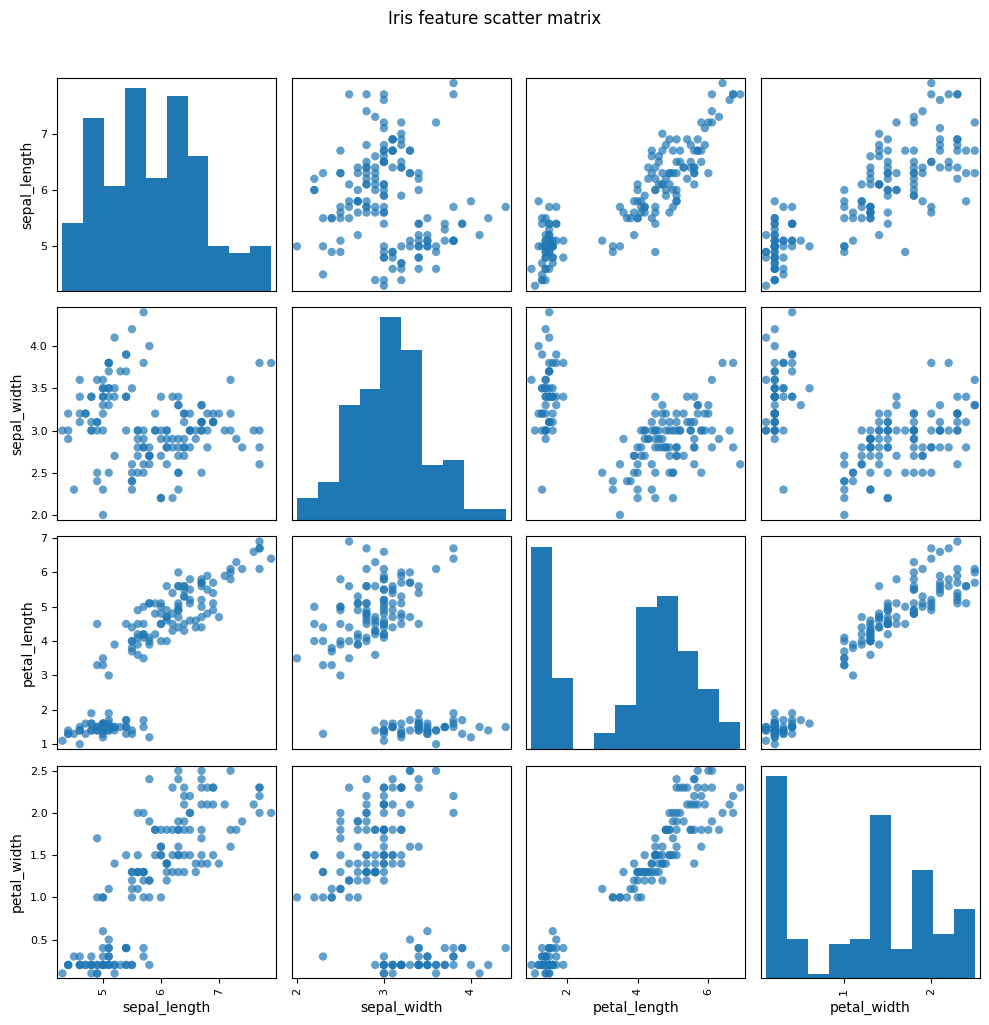

In [0]:
# A scatter-matrix provides a similar exploratory view to a Seaborn pairplot.
# The diagonal shows each feature's distribution; other panels show feature relationships.
axes = pd.plotting.scatter_matrix(
    df[numeric_columns],
    figsize=(10, 10),
    diagonal="hist",
    alpha=0.7,
    marker="o"
)
plt.suptitle("Iris feature scatter matrix", y=1.02)
plt.tight_layout()
plt.show()

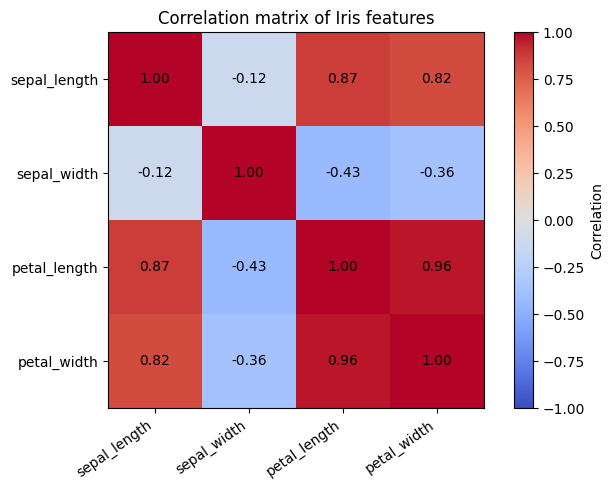

In [0]:
# Calculate and visualise correlations between numeric features.
correlation = df[numeric_columns].corr()

fig, ax = plt.subplots(figsize=(7, 5))
image = ax.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(numeric_columns)))
ax.set_yticks(range(len(numeric_columns)))
ax.set_xticklabels(numeric_columns, rotation=35, ha="right")
ax.set_yticklabels(numeric_columns)
ax.set_title("Correlation matrix of Iris features")

# Write each correlation value inside its cell.
for row in range(len(numeric_columns)):
    for col in range(len(numeric_columns)):
        ax.text(col, row, f"{correlation.iloc[row, col]:.2f}",
                ha="center", va="center")

fig.colorbar(image, ax=ax, label="Correlation")
plt.tight_layout()
plt.show()

## Step 5: Prepare the data for machine learning

Separate the input features (`X`) from the target label (`y`).

We will scale the numeric features using `StandardScaler`. Scaling puts features on a comparable scale, which is particularly useful for Logistic Regression.

**Important leakage prevention:** We will put `StandardScaler` inside a Scikit-Learn `Pipeline`. The scaler is fitted only on the training data during `.fit()`, then applied to the test data. This prevents information from the test set leaking into training.

A Decision Tree does not generally require feature scaling, but we include the scaler in its pipeline to keep the requested workflow consistent.

In [0]:
# Select the four measurement columns as model inputs.
X = df[["sepal_length", "sepal_width", "petal_length", "petal_width"]]

display(X)

sepal_length,sepal_width,petal_length,petal_width
5.1,3.5,1.4,0.2
4.9,3.0,1.4,0.2
4.7,3.2,1.3,0.2
4.6,3.1,1.5,0.2
5.0,3.6,1.4,0.2
5.4,3.9,1.7,0.4
4.6,3.4,1.4,0.3
5.0,3.4,1.5,0.2
4.4,2.9,1.4,0.2
4.9,3.1,1.5,0.1


In [0]:
# Select the species column as the answer the model must learn to predict.
y = df["species"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Target classes:", sorted(y.unique()))

Feature matrix shape: (149, 4)
Target shape: (149,)
Target classes: ['setosa', 'versicolor', 'virginica']


## Step 6: Split the data

Use an 80/20 train/test split:
- 80% of records are used to train the models.
- 20% are held back to evaluate performance on unseen records.

`stratify=y` keeps the proportions of the three species approximately consistent in both sets. `random_state=42` makes the split reproducible.

In [0]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,       # Reserve 20% for final testing.
    random_state=42,      # Make the split reproducible.
    stratify=y            # Preserve class proportions in both sets.
)

print("Training feature rows:", X_train.shape[0])
print("Testing feature rows:", X_test.shape[0])



Training feature rows: 119
Testing feature rows: 30


In [0]:
print("\\nSpecies proportions in training data:")
print(y_train.value_counts(normalize=True).round(3))

print("\\nSpecies proportions in testing data:")
print(y_test.value_counts(normalize=True).round(3))

\nSpecies proportions in training data:
species
setosa        0.336
versicolor    0.336
virginica     0.328
Name: proportion, dtype: float64
\nSpecies proportions in testing data:
species
versicolor    0.333
virginica     0.333
setosa        0.333
Name: proportion, dtype: float64


## Phase 3 — Build the models

### Step 7: Choose the machine learning algorithms

We will compare two classification algorithms:

**Logistic Regression**
- A classification algorithm that estimates the probability of each class.
- Feature scaling is important for a well-behaved optimisation process.
- We set `max_iter=1000` to allow sufficient iterations for convergence.

**Decision Tree**
- Learns a sequence of feature-based decision rules.
- Can model non-linear relationships.
- A very deep tree may overfit, so we start with `max_depth=4` as a simple constraint.

### Step 8: Train the models

Each pipeline performs scaling (where applicable) and model fitting. Calling `.fit()` teaches the model using only the training data.

In [0]:
# Build a Logistic Regression pipeline.
logistic_model = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])



In [0]:
# Build a Decision Tree pipeline.
# The scaler is included for consistency, although trees do not require scaling.
tree_model = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("classifier", DecisionTreeClassifier(max_depth=4, random_state=42))
])



In [0]:
# Train both models using the training dataset.
logistic_model.fit(X_train, y_train)


,steps,"[('scaler', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0


In [0]:
tree_model.fit(X_train, y_train)

,steps,"[('scaler', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,criterion,'gini'
,splitter,'best'
,max_depth,4
,min_samples_split,2


In [0]:
print("Both models have been trained successfully")

Both models have been trained successfully


### Step 9: Evaluate the models

Use the held-out test data to generate predictions. We report:
- **Accuracy:** proportion of all predictions that are correct.
- **Precision:** how often predictions for a class are correct.
- **Recall:** how many actual examples of a class are found.
- **F1-score:** harmonic balance between precision and recall.



In [0]:
# Generate predictions for records the models did not see during training.
logistic_predictions = logistic_model.predict(X_test)
tree_predictions = tree_model.predict(X_test)

# Calculate weighted evaluation metrics for each model.
results = []

for model_name, predictions in [
    ("Logistic Regression", logistic_predictions),
    ("Decision Tree", tree_predictions)
]:
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (weighted)": precision_score(y_test, predictions, average="weighted", zero_division=0),
        "Recall (weighted)": recall_score(y_test, predictions, average="weighted", zero_division=0),
        "F1-score (weighted)": f1_score(y_test, predictions, average="weighted", zero_division=0)
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

Model,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted)
Logistic Regression,0.9333,0.9333,0.9333,0.9333
Decision Tree,0.9333,0.9333,0.9333,0.9333


In [0]:
# Detailed classification report for Logistic Regression.
print("LOGISTIC REGRESSION — CLASSIFICATION REPORT")
print(classification_report(y_test, logistic_predictions, zero_division=0))


LOGISTIC REGRESSION — CLASSIFICATION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [0]:
# Detailed classification report for Decision Tree.
print("DECISION TREE — CLASSIFICATION REPORT")
print(classification_report(y_test, tree_predictions, zero_division=0))

DECISION TREE — CLASSIFICATION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



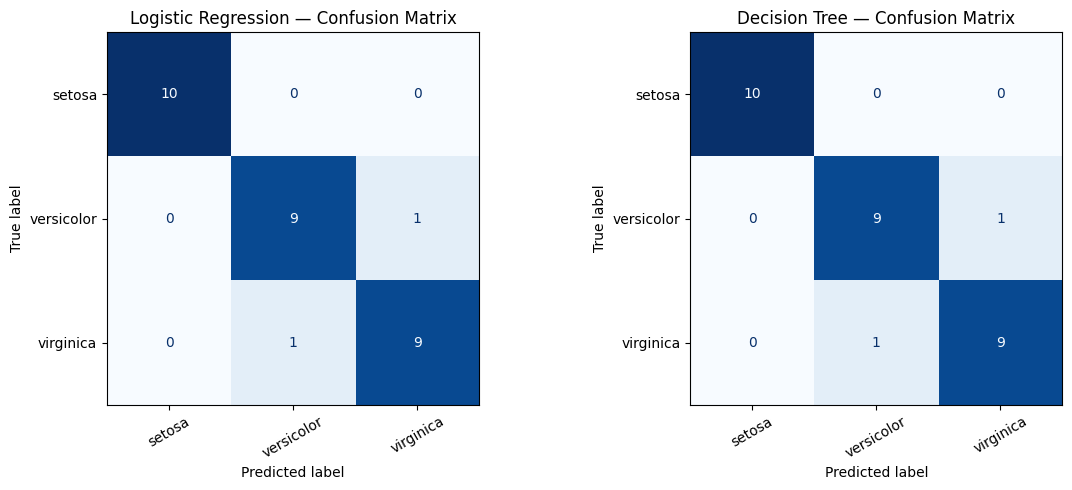

In [0]:
# Plot a confusion matrix for each model.
# Rows represent actual species; columns represent predicted species.
class_names = sorted(y.unique())

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, model_name, predictions in [
    (axes[0], "Logistic Regression", logistic_predictions),
    (axes[1], "Decision Tree", tree_predictions)
]:
    cm = confusion_matrix(y_test, predictions, labels=class_names)
    display_obj = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )
    display_obj.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )
    ax.set_title(f"{model_name} — Confusion Matrix")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

### Step 10: Compare and improve the models

Compare the weighted metrics and confusion matrices. A good model should perform well across all three species, not just achieve a high overall accuracy.




In [0]:
# Display the models ranked by weighted F1-score.
ranked_results = results_df.sort_values(
    by="F1-score (weighted)",
    ascending=False
).reset_index(drop=True)

display(ranked_results.round(4))



Model,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted)
Logistic Regression,0.9333,0.9333,0.9333,0.9333
Decision Tree,0.9333,0.9333,0.9333,0.9333


In [0]:
# Identify the model with the highest weighted F1-score on this test split.
best_model_name = ranked_results.loc[0, "Model"]
print("Best model by weighted F1-score on this test split:", best_model_name)



Best model by weighted F1-score on this test split: Logistic Regression


Logistic Regression is only selected because of how pandas breaks ties during sorting, not because its score is actually higher.

Why It Won the Tie

• Original List Order: In your previous cell, you added "Logistic Regression" to the results list first (row index 0) and "Decision Tree" second (row index 1).
• Stable Sorting Behavior: When sort_values() encounters identical numbers (0.9333 vs. 0.9333), pandas preserves the original row order by default. Because Logistic Regression was entered first, it stays at the top (index 0).
• Blind First-Row Selection: In cell 40, ranked_results.loc[0, "Model"] simply grabs whatever model sits in the very first row without checking if second place has the exact same score.


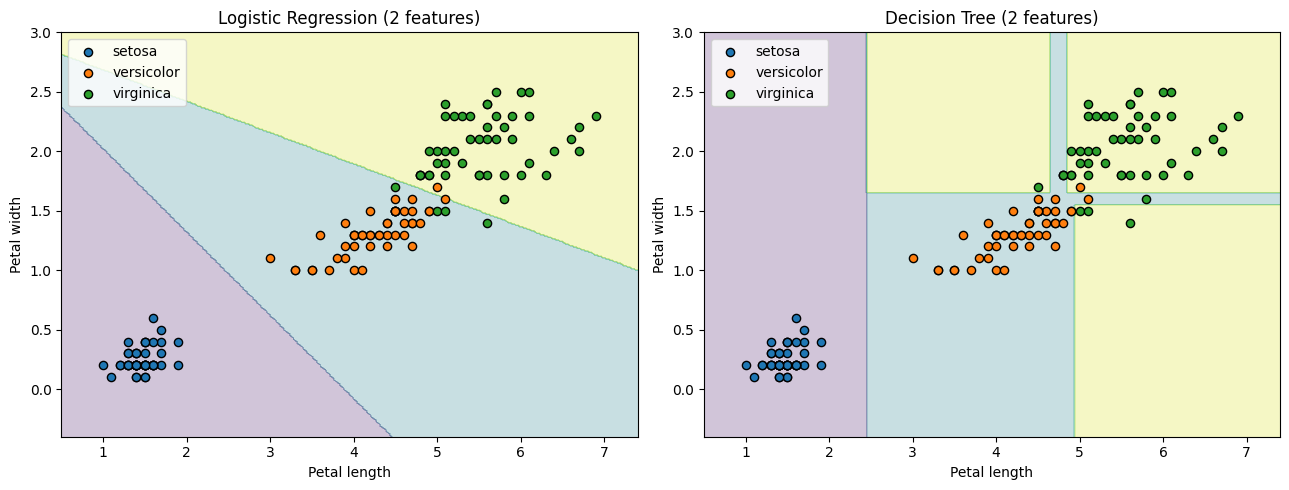

In [0]:
# Select only petal length and petal width for a two-dimensional plot.
boundary_features = ["petal_length", "petal_width"]
X_2d = df[boundary_features]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X_2d,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Fit two separate models on the two selected features.
logistic_2d = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])
tree_2d = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("classifier", DecisionTreeClassifier(max_depth=4, random_state=42))
])

logistic_2d.fit(X2_train, y2_train)
tree_2d.fit(X2_train, y2_train)

# Create a fine grid covering the range of the two features.
x_min, x_max = X_2d["petal_length"].min() - 0.5, X_2d["petal_length"].max() + 0.5
y_min, y_max = X_2d["petal_width"].min() - 0.5, X_2d["petal_width"].max() + 0.5
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)
grid = pd.DataFrame({
    "petal_length": xx.ravel(),
    "petal_width": yy.ravel()
})

# Use the fitted models to predict the class at each point in the grid.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, model, model_name in [
    (axes[0], logistic_2d, "Logistic Regression (2 features)"),
    (axes[1], tree_2d, "Decision Tree (2 features)")
]:
    grid_predictions = model.predict(grid)
    # Convert predicted class names to numeric codes for the background regions.
    class_to_number = {name: number for number, name in enumerate(class_names)}
    region_values = np.array([class_to_number[name] for name in grid_predictions])
    region_values = region_values.reshape(xx.shape)

    ax.contourf(xx, yy, region_values, alpha=0.25, cmap="viridis")
    for class_name in class_names:
        class_rows = df[df["species"] == class_name]
        ax.scatter(
            class_rows["petal_length"],
            class_rows["petal_width"],
            label=class_name,
            edgecolor="black",
            s=35
        )
    ax.set_title(model_name)
    ax.set_xlabel("Petal length")
    ax.set_ylabel("Petal width")
    ax.legend()

plt.tight_layout()
plt.show()

## Phase 4 — Operate the model

### Step 11: Deploy the model



In [0]:
import joblib

# Save the complete pipelines, including their fitted scalers and classifiers.
joblib.dump(logistic_model, "iris_logistic_regression_pipeline.joblib")
joblib.dump(tree_model, "iris_decision_tree_pipeline.joblib")

print("Model pipelines saved.")

Model pipelines saved.


### Step 12: Monitor the model

 


## Final Conclusion

The objective of this project was to develop and benchmark a supervised multi-class classification pipeline capable of predicting Iris flower species using four measurements: sepal length, sepal width, petal length and petal width.

Following the 12-step Machine Learning Process, the dataset was loaded, inspected, cleaned and explored through exploratory data analysis (EDA). One duplicate record was identified and removed, leaving 149 observations with no missing values. The dataset was subsequently divided into 80% training data (119 records) and 20% testing data (30 records), using stratified sampling to maintain the distribution of the three flower species.

Two classification algorithms, Logistic Regression and Decision Tree, were implemented using Scikit-Learn pipelines. StandardScaler was incorporated into the pipelines to standardise the input features and prevent data leakage by fitting the scaler exclusively on the training data.

The evaluation results showed that both models achieved an accuracy of **93.33%**, with weighted precision, recall and F1-scores of **93.33%**. Their classification reports produced identical results across all three species. Both models correctly classified all 10 Iris-setosa observations, while achieving 90% precision, recall and F1-score for Iris-versicolor and Iris-virginica.

The confusion matrices confirmed that each model correctly classified 28 out of the 30 test observations, with two misclassifications occurring between Iris-versicolor and Iris-virginica.

Based on these findings, both algorithms demonstrated strong classification performance on the selected test dataset. Neither model showed a measurable performance advantage over the other using the evaluation metrics considered. Logistic Regression is a reasonable baseline model, while Decision Tree provides an alternative that can represent classification decisions through interpretable rules.

For further improvement, I would recommend experimenting with hyperparameter tuning, cross-validation and additional performance comparisons to assess model consistency across different data splits.

Finally, although the trained pipelines were saved for potential future use, actual deployment and continuous monitoring remain future considerations. In a production environment, monitoring would include checking incoming data for data drift and evaluating prediction accuracy as new labelled observations become available.

**Overall, this project strengthened my practical understanding of supervised machine learning, data preprocessing, feature scaling, model training, performance evaluation and the importance of following a structured end-to-end machine learning workflow.**

